# 1. Importing libraries and dataset and dictionary

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

In [279]:
# Importing Dataset
df = pd.read_csv("Salary_Data_Based_country_and_race.csv", index_col="Unnamed: 0")
# Renaming columns
df.columns = df.columns.str.replace(" ","_").str.lower()
# Printing first 5 rows
df.head()

,age,gender,education_level,job_title,years_of_experience,salary,country,race
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0,UK,White
1,28.0,Female,Master's,Data Analyst,3.0,65000.0,USA,Hispanic
2,45.0,Male,PhD,Senior Manager,15.0,150000.0,Canada,White
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0,USA,Hispanic
4,52.0,Male,Master's,Director,20.0,200000.0,USA,Asian


In [280]:
# Inspecting Dataset
print(f"The dataframe contains {df.isnull().sum().sum()} null values.")
print("=============== Total number of null values in each feature  ===============")
df_null = df.isnull().sum()
df_null = df_null[df_null>0]
df_null


The dataframe contains 17 null values.
=============== Total number of null values in each feature  ===============


age                    2
gender                 2
education_level        3
job_title              2
years_of_experience    3
salary                 5
dtype: int64

In [281]:
# Dropping null values
df = df.dropna()

# Reseting index
df.reset_index(drop =True, inplace=True)

In [282]:
# Dataframe shape
print(f"The dataframe contains {df.shape[0]} rows / recods, and {df.shape[1]} features / variables.")

The dataframe contains 6698 rows / recods, and 8 features / variables.


In [283]:
# Checking data types
df.dtypes

age                    float64
gender                     str
education_level            str
job_title                  str
years_of_experience    float64
salary                 float64
country                    str
race                       str
dtype: object

# Data Inspection and Cleaning

In [284]:
np.unique(df["education_level"])

array(["Bachelor's", "Bachelor's Degree", 'High School', "Master's",
       "Master's Degree", 'PhD', 'phD'], dtype=object)

In [285]:
df["education_level"] = np.where(df["education_level"]=="Master's","Master's Degree",
         np.where(df["education_level"] == "Bachelor's","Bachelor's Degree",
         np.where(df["education_level"] == "phD","PhD",df["education_level"])))

In [286]:
np.unique(df["race"])

array(['African American', 'Asian', 'Australian', 'Black', 'Chinese',
       'Hispanic', 'Korean', 'Mixed', 'Welsh', 'White'], dtype=object)

In [287]:
np.unique(df["country"])

array(['Australia', 'Canada', 'China', 'UK', 'USA'], dtype=object)

In [288]:
np.unique(df["gender"])

array(['Female', 'Male', 'Other'], dtype=object)

**Note:** Now that we have checked the features within the dataset and replace the values that contained typo and dropped the null values, I will proceed by plotting some charts to get some insights from our dataset.

----

In [289]:
df.to_csv("data_cleaned.csv")

----

# EDA visualizations

In [391]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

df = pd.read_csv("data_cleaned.csv", index_col ="Unnamed: 0")

## Age feature

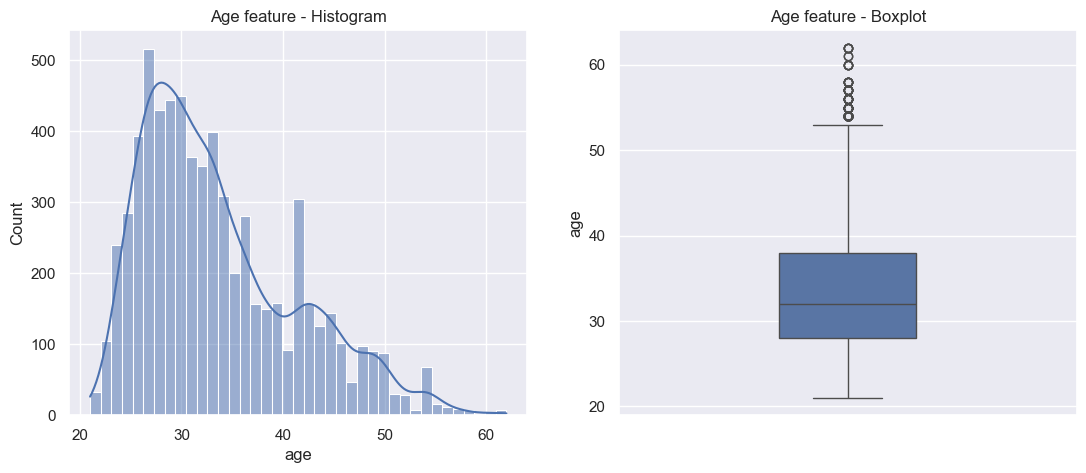

,count,mean,std,min,25%,50%,75%,max
age,6698.0,33.623022,7.615784,21.0,28.0,32.0,38.0,62.0


In [392]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.title("Age feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["age"], width=0.3)
plt.title("Age feature - Boxplot")
plt.show()

df[["age"]].describe().T

**Findings:** I can confirm that the age feature is right (positive) skewed for which:

* The 50% of the employees are between 28 years and 38 years old (Interquartile Range)
* The youngest employee is 21 years old, whereas the elderly one is 62 years old
* The The standard deviation is 7.61 years old.

---

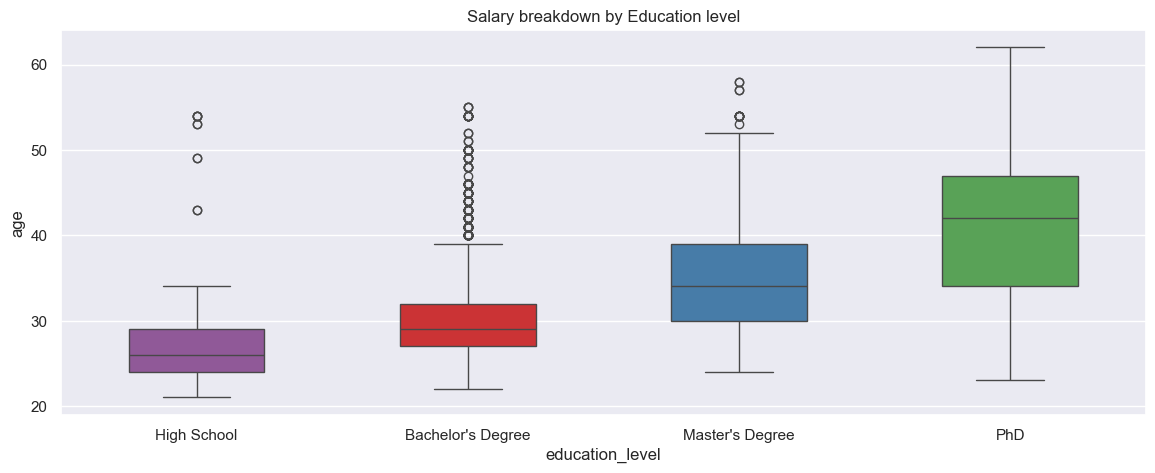

,count,mean,std,min,25%,50%,75%,max
education_level,,,,,,,,
Bachelor's Degree,3021.0,30.26,5.14,22.0,27.0,29.0,32.0,55.0
High School,448.0,26.85,4.65,21.0,24.0,26.0,29.0,54.0
Master's Degree,1860.0,35.17,6.43,24.0,30.0,34.0,39.0,58.0
PhD,1369.0,41.15,7.90,23.0,34.0,42.0,47.0,62.0


In [393]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="age",
            x="education_level",
            width=0.5,
           order=["High School", "Bachelor's Degree", "Master's Degree", "PhD"],
            hue="education_level",
           palette="Set1")
plt.title("Salary breakdown by Education level")
plt.show()

df.groupby("education_level")["age"].describe().round(2)

In [394]:
df["education_level"].value_counts()

education_level
Bachelor's Degree    3021
Master's Degree      1860
PhD                  1369
High School           448
Name: count, dtype: int64

**Findings:** By looking at the results obtained in the boxplot and the kdeplot, I can confirm that the **average age for employees holding a High School, Bachelor's, Master, and PhD Degree are 26.985, 30.26, 35.17, and 41.15 respectively**.

---

## Salary feature

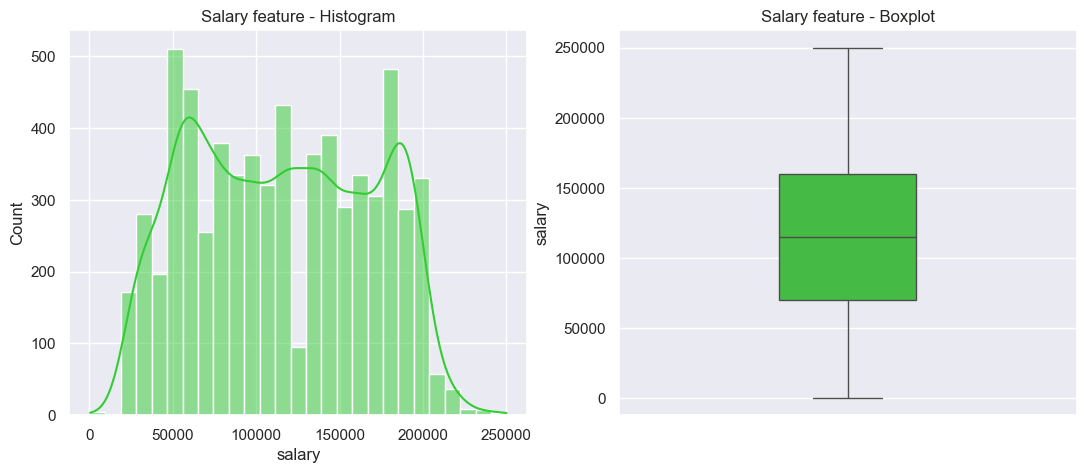

,count,mean,std,min,25%,50%,75%,max
salary,6698.0,115329.253061,52789.792507,350.0,70000.0,115000.0,160000.0,250000.0


In [395]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True, color="limegreen")
plt.title("Salary feature - Histogram")
plt.subplot(1,2,2)
sns.boxplot(y=df["salary"], width=0.3, color="limegreen")
plt.title("Salary feature - Boxplot")
plt.show()

df[["salary"]].describe().T

**Findings:** By looking at the plots obtained, I can confirm that the salary feature is **binomial**, for which it means there are 2 peaks between the 50k and 60k, and another one between 180k and 200k.

* The 50% of the employees earns between 70K and 160K
* The employee who earns the least has a salary of 350 dollars whereas the employee that who earns the most has a salary of 250K.

---

## Salary / Education level boxplot

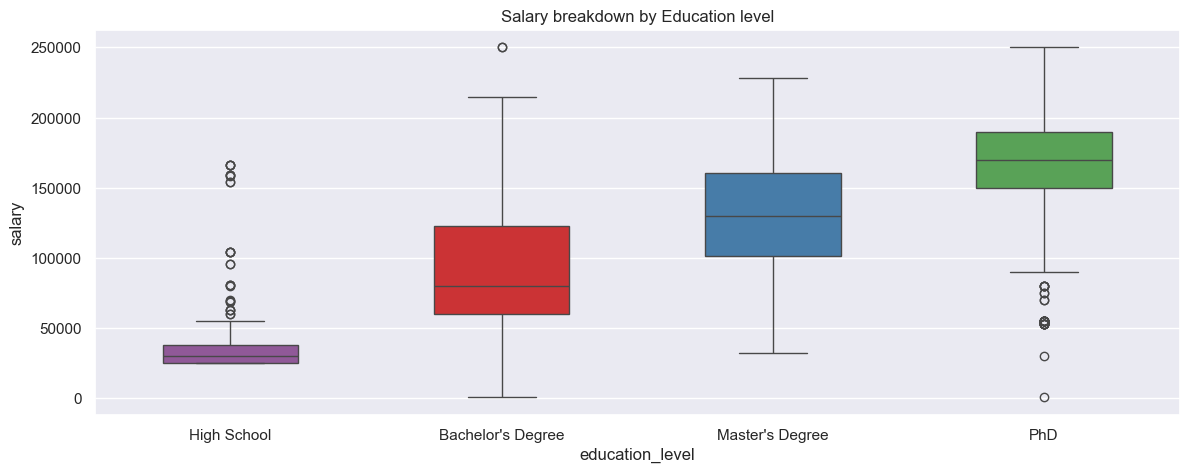

,count,mean,std,min,25%,50%,75%,max
education_level,,,,,,,,
Bachelor's Degree,3021.0,95082.91,44091.79,350.0,60000.0,80000.0,122485.0,250000.0
High School,448.0,36706.69,22549.13,25000.0,25000.0,30000.0,38000.0,166109.0
Master's Degree,1860.0,130112.06,40640.82,32000.0,101186.0,130000.0,160244.0,228000.0
PhD,1369.0,165651.46,34339.75,579.0,150000.0,170000.0,190000.0,250000.0


In [396]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df, y="salary",
            x="education_level",
            width=0.5,
           order=["High School", "Bachelor's Degree", "Master's Degree", "PhD"],
            hue="education_level",
           palette="Set1")
plt.title("Salary breakdown by Education level")
plt.show()

df.groupby("education_level")["salary"].describe().round(2)

**Note:** I can confirm that there is an increase of salary in each education level by looking at the salary range for which the Interquartile Range is located.

* **The frequency among the different education level is imbalanced.** (I can confirm this by looking at the count column)
* If we look up to the employees that only have a **High School degree**, I could say that the 50% of the them earn between 25K and 38K;
* The 50% of employees that hold a **Bachelor's Degree** earn between 60K and 122K;
* 50% of the employees that hold a **Master's Degree** earn between 100K and 150K;
* and finally, employees that hold a **PhD title** earn between 150K and 190K.

In each education level, I can confirm an improvement in the salary by looking at these values.

----

## Years of experience / Salary

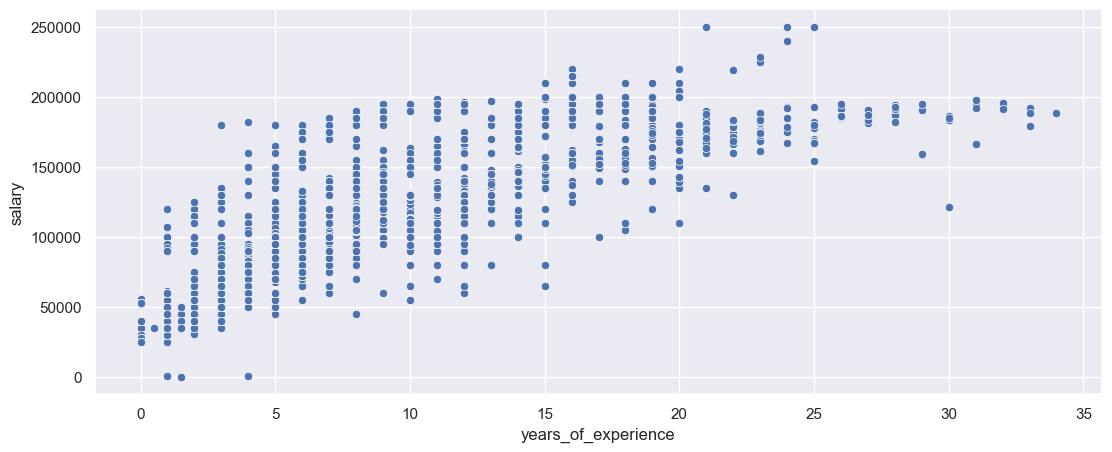

In [397]:
plt.figure(figsize=(13,5))
sns.scatterplot(data=df, x="years_of_experience", y="salary")
plt.show()

**Note:** Here, I am looking at the relationship between the features *Years of experience* and *Salary*. The final aim about this is to understand the relationship between these features, and I could say that as more years of experience the employee has higher would be the salary.

---

# Encoding

In [398]:
gender = {"Male":0, "Female":1,"Other":2}
df["gender"] = df["gender"].map(gender)

In [399]:
education = {"Bachelor's Degree":1, 'High School':0, "Master's Degree":2, 'PhD':3}
df["education_level"] = df["education_level"].map(education)

In [400]:
df1 = df.groupby("job_title")["salary"].median().sort_values().reset_index()


dic_job = {}
for i in range(len(df1["job_title"])):
    dic_job[df1["job_title"].iloc[i]] = i

df["job_title"] = df["job_title"].map(dic_job)

In [401]:
countries = {"USA":0, "Canada":1, "UK":2, "Australia":3, "China": 4}
df["country"] = df["country"].map(countries)

In [402]:
df1 = df.groupby("race")["salary"].median().sort_values().reset_index()


dic_race = {}
for i in range(len(df1["race"])):
    dic_race[df1["race"].iloc[i]] = i

df["race"] = df["race"].map(dic_race)

---

### Check Point

In [403]:
df.to_csv("data_encoded.csv")

----

# Regular ML models

The dataset that I selected provides employees' information in regards of "Age", "Gender", **"Education Level"**, "Job title", "Years of experience", "Country", "Salary", and "Race". 

My scope in this project is to create 2 different type of machine learning models: **Classification**

The final aim of classification models would be predict what education level the employee has based on the dependent features (Gender, age, job title, years of experience, salary and country). I will execute multiples models, explain the results obtained and select the one that best performs.


In [432]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme()

import warnings 
warnings.filterwarnings('ignore')


## Classification models

In [433]:
df = pd.read_csv("data_encoded.csv", index_col="Unnamed: 0")

# Reordering DataFrame 
df = df[['age', 'gender', 'job_title', 'years_of_experience',
       'salary','race','country','education_level']]

### Executing scaling

By following good practices learned in Data preparation

#### Years of experience

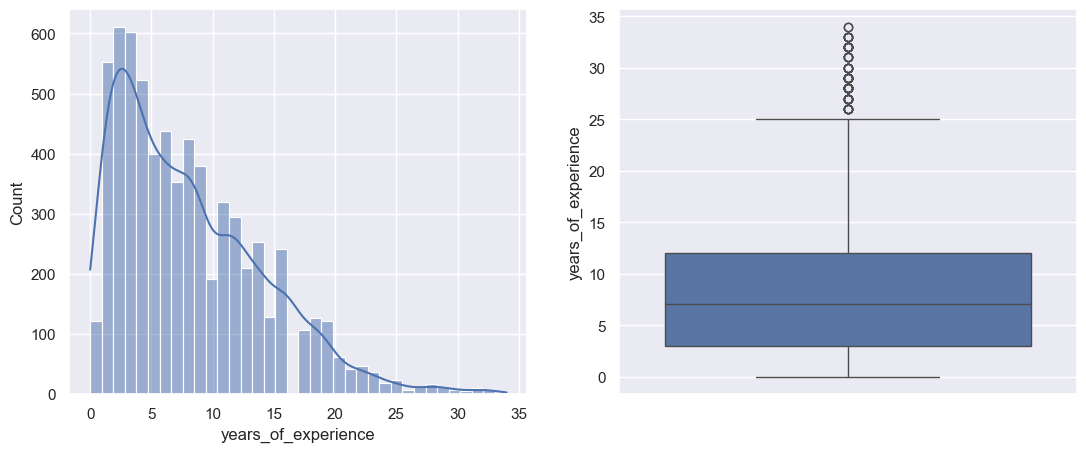

In [434]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["years_of_experience"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["years_of_experience"])
plt.show()

**Note:** Since the data does not have outlier, it's not normally distributed, and it's obviously skewed, I will proceed by executing mixmax scalling.

In [435]:
df["years_of_experience"] = preproc.minmax_scale(df["years_of_experience"])

#### salary

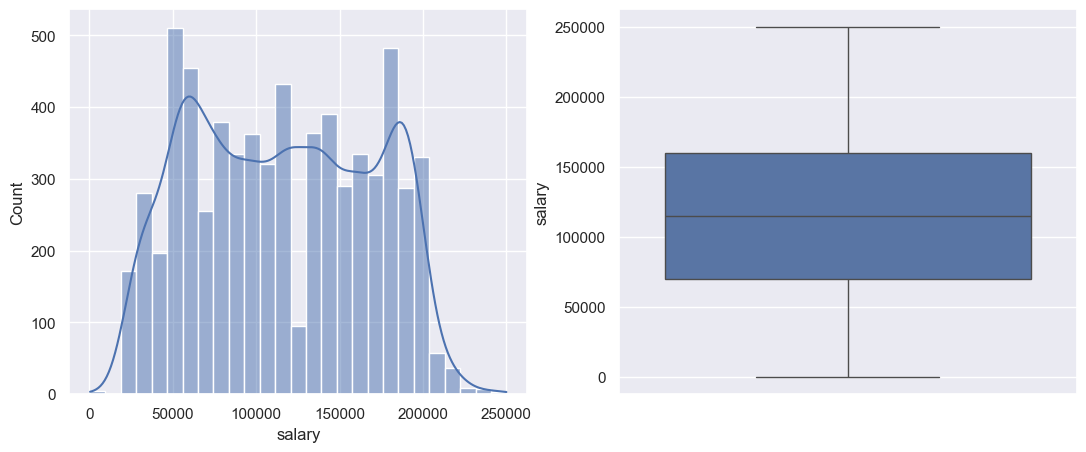

In [436]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["salary"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["salary"])
plt.show()

**Note:** Since the data does not have outlier, it's not normally distributed, and it's obviously skewed, I will proceed by executing mixmax scalling.

In [437]:
df["salary"] = preproc.minmax_scale(df[["salary"]])

#### Age

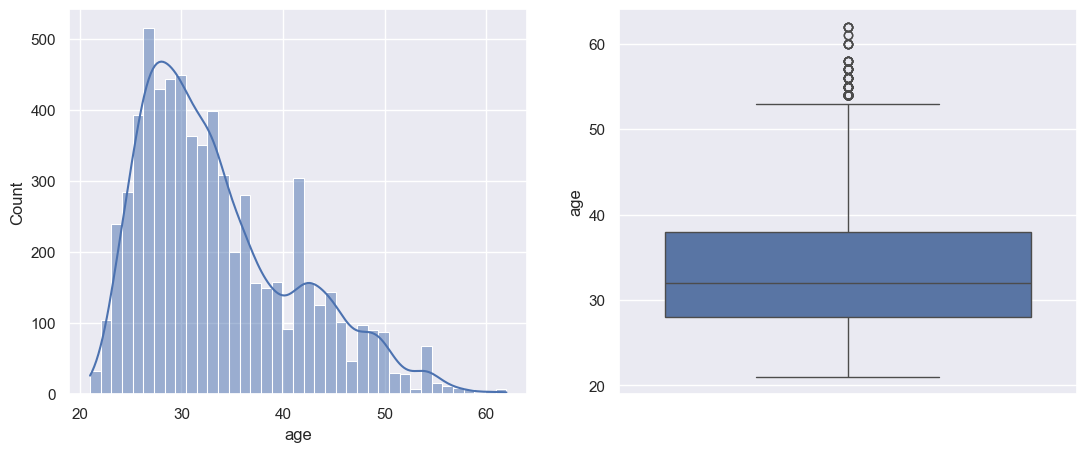

In [438]:
plt.figure(figsize=(13,5))
plt.subplot(1,2,1)
sns.histplot(df["age"], kde=True)
plt.subplot(1,2,2)
sns.boxplot(df["age"])
plt.show()

In [439]:
df["age"] = preproc.minmax_scale(df[["age"]])

----

### Defining Classifier for ML models

In [440]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs = -1),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

# X = independent variables | y = dependent variables
X = df.drop(columns=["education_level"])
y = df["education_level"]

### Train Test Split - Test size = 0.05 | 

In [441]:
# Splitting into traininng and testing 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05, random_state = 42, stratify=y)

X_train.shape , X_test.shape , y_train.shape , y_test.shape 

((6363, 7), (335, 7), (6363,), (335,))

In [443]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])

print("Model Performance Metrics on Test Set - Test Size 0.05:")
print(results_df)

Model Performance Metrics on Test Set - Test Size 0.05:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.764179   0.764892  0.764179  0.764039
1        Decision Tree  0.940299   0.940777  0.940299  0.940361
2        Random Forest  0.937313   0.938164  0.937313  0.937322


In [444]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.597937
1        Decision Tree          0.611514
2        Random Forest          0.663172


**Note:** after applyinh SMOTE, I saw that my results were not changing that much. That is why I decided to add the parameter "Stratify" within the function **train Test Split**.

**Findings:**

---

### Train Test Split - Test size = 0.15

In [445]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42, stratify = y)

X_train.shape , X_test.shape , y_train.shape , y_test.shape 

((5693, 7), (1005, 7), (5693,), (1005,))

In [446]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set - Test Size 0.15:")
print(results_df)

Model Performance Metrics on Test Set - Test Size 0.15:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.741294   0.738021  0.741294  0.738730
1        Decision Tree  0.925373   0.926553  0.925373  0.925729
2        Random Forest  0.924378   0.924509  0.924378  0.924425


In [447]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.597937
1        Decision Tree          0.611514
2        Random Forest          0.663172


**Findings:**

___

### Train Test Split - Test size = 0.25

In [448]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42, stratify = y)

X_train.shape , X_test.shape , y_train.shape , y_test.shape 

((5023, 7), (1675, 7), (5023,), (1675,))

In [449]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set - Test size 0.25:")
print(results_df)

Model Performance Metrics on Test Set - Test size 0.25:
                 Model  Accuracy  Precision    Recall  F1 Score
0  k-Nearest Neighbors  0.739104   0.736390  0.739104  0.736461
1        Decision Tree  0.920597   0.920564  0.920597  0.920564
2        Random Forest  0.927164   0.927006  0.927164  0.927031


In [267]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.600625
1        Decision Tree          0.621367
2        Random Forest          0.659440


**Findings:**

-----

## Grid Search

In [268]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs = -1),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
}

# X = independent variables | y = dependent variables
X = df.drop(columns=["education_level"])
y = df["education_level"]

In [147]:
# Define hyperparameter grids for each classifier
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "max_depth": [None, 10, 20, 30]
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20, 30]
    },
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9]
    },
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ['linear', 'rbf']
    }
}

In [148]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_])

Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Decision Tree...
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [149]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                 Model  Accuracy  Precision    Recall  F1 Score  \
0  k-Nearest Neighbors  0.737910   0.732603  0.737910  0.732117   
1        Decision Tree  0.922388   0.922377  0.922388  0.922356   
2        Random Forest  0.925970   0.925954  0.925970  0.925939   

                          Best Parameters  
0                      {'n_neighbors': 7}  
1                       {'max_depth': 20}  
2  {'max_depth': 20, 'n_estimators': 100}  


In [150]:
# Cross-validation for accuracy on the full dataset using best models
cv_results = []
for name, classifier in classifiers.items():
    # Get the best model from GridSearchCV
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv=5, n_jobs=-1, verbose=2)
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
    
    cv_scores = cross_val_score(best_model, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits


In [151]:
# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores after GridSearchCV:")
print(cv_results_df)


Cross-Validation Accuracy Scores after GridSearchCV:
                 Model  Mean CV Accuracy
0  k-Nearest Neighbors          0.611819
1        Decision Tree          0.613603
2        Random Forest          0.665413


CCT College Dublin (2026) - Class code from Saturday Class | Comparison Classification Model

-----